# Company risk: factor benchmark

The original study is a completed historical analysis. Historical evaluation blocks were reused; they are not fresh holdouts.

Read the saved outputs without executing this notebook. Original code cells, their metadata, execution counts and outputs are preserved. This package supplies selected scientific evidence and context; the code retains its original source environment and frozen-input dependencies. It is not a standalone reproduction environment. See the [notebook index](README.md).


## Research question: Forward stock-risk tests

**Question:** Does an extra characteristic improve subsequent risk forecasts?

Future residuals subtract formation-estimated FF5-plus-momentum predictions without refitting inside the future quarter. Cross-sectional association uses observed outcomes; forecasting trains only on earlier completed quarters, with train-only scaling and category construction.

**Where this fits:** These results answer the stock-level question. Read these alongside [portfolio covariance](portfolio-covariance.ipynb) and the [cross-study synthesis](../FINDINGS.md). Percentages are changes in log-volatility forecast error, not risk reduction.
This notebook defines and runs the forward-risk calculations directly. Run from top
to bottom using the project environment and frozen local inputs. The function bodies
below come from `src/quiet_index_500/forward_tests.py`; they are executable local
definitions, so editing a function here changes this notebook's calculations.
Shared settings, the calendar and data loaders remain package imports.

The specification is in `docs/TEST_FREEZE.md`; interpretation is in
`docs/findings/forward_tests.md`. Both the 504-session main exposure window and
252-session sensitivity window are run. Tables are recomputed in memory; executing
this notebook does not overwrite the saved research CSVs. Rebuilds preserve these authored cells. If you change a method permanently, update
the corresponding package implementation as well.

Existing figures appear beside the concepts they illustrate. Early tables and
charts show saved evidence for orientation; section 5 independently recomputes
the results and section 6 exposes a fitted equation. The publication figures and their supporting CSVs/manifests are already tracked
under `results/publication/`. All figures remain static
illustrations when notebook functions are edited.


### Existing method notes

Fixed formation coefficients define future residual volatility. Association uses observed future outcomes; expanding forecasts use only earlier completed quarters. Paired comparisons share their eligible companies. Inference preserves quarter-level shocks and conditions on estimated exposures. See docs/findings/forward_tests.md for interpretation and the six-quarter confirmation limit.


### Method map: define the target, then forecast

`forward_outcomes` applies fixed formation coefficients. `evaluate_comparison` chooses a shared complete sample and trains only on previously completed outcomes. `fit_predict_linear` learns scaling and categories from training data; `summarize_comparisons` averages quarterly scores and quantifies time dependence. The functions are defined and run locally below; saved figures provide orientation.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image, display

from quiet_index_500 import settings
from quiet_index_500.foundation import calendar, loader

In [2]:
standard_style_columns = ['m3_smb', 'm3_hml', 'm3_rmw', 'm3_cma', 'm3_mom']
baseline_columns = ['m3_mkt_rf', 'own_momentum', 'trailing_residual_volatility']
outcome_columns = ['log_forward_total_volatility', 'log_forward_residual_volatility']
factor_names = ['mkt_rf', 'smb', 'hml', 'rmw', 'cma', 'mom']

## 1. Following-quarter risk outcomes

For company $i$ formed at quarter-end $t$, let $Q(t+1)$ be the following
calendar quarter. The saved formation FF5-plus-momentum coefficients are held fixed:

$$e^{\mathrm{fixed}}_{i,d\mid t}
=r_{i,d}-r_{f,d}-\widehat\alpha^{(3)}_{i,t}
-\sum_{k\in\{MKT,SMB,HML,RMW,CMA,MOM\}}
\widehat\beta^{(3)}_{i,k,t}f_{k,d},\qquad d\in Q(t+1).$$

$$\sigma^{\mathrm{total}}_{i,t+1}
=\sqrt{252}\,\operatorname{sd}_{d\in Q(t+1)}(r_{i,d}),\qquad
\sigma^{\mathrm{residual}}_{i,t+1}
=\sqrt{252}\,\operatorname{sd}_{d\in Q(t+1)}(e^{\mathrm{fixed}}_{i,d\mid t}).$$

Each target is $y^{(a)}_{i,t+1}=\log\sigma^{(a)}_{i,t+1}$, fitted separately
for total and residual volatility. `sd` is the sample standard deviation (`ddof=1`)
over nonmissing observations. Each outcome needs at least 40 valid days; only
complete factor-covered quarters are evaluated. These are realized targets for
training and scoring; their future returns and factors are not forecast inputs.


In [3]:
def forward_outcomes(company_panel, daily_returns, factors):
    """Future-quarter sample volatility, with formation model-3 coefficients held fixed."""
    panel = company_panel.copy()
    panel["formation_date"] = pd.to_datetime(panel.formation_date)
    records = []
    for formation, companies in panel.groupby("formation_date", sort=True):
        if not calendar.following_quarter_complete(formation, factors.index.max()):
            continue
        sessions = calendar.following_quarter_sessions(daily_returns.index, formation)
        future_returns = daily_returns.reindex(sessions)
        future_factors = factors.reindex(sessions)
        design = np.column_stack([np.ones(len(sessions)), future_factors[factor_names].to_numpy()])
        for _, company in companies.iterrows():
            ticker_returns = future_returns[company.ticker]
            coefficients = company[["m3_alpha", *[f"m3_{factor}" for factor in factor_names]]].to_numpy(dtype=float)
            fixed_prediction = pd.Series(design @ coefficients, index=sessions)
            residual = ticker_returns - future_factors.rf - fixed_prediction
            total_days, residual_days = ticker_returns.notna().sum(), residual.notna().sum()
            total_vol = ticker_returns.std(ddof=1) * np.sqrt(settings.annualisation_sessions) if total_days >= settings.forward_outcome_minimum_valid_days else np.nan
            residual_vol = residual.std(ddof=1) * np.sqrt(settings.annualisation_sessions) if residual_days >= settings.forward_outcome_minimum_valid_days else np.nan
            records.append({"formation_date": formation, "ticker": company.ticker, "cik": company.cik,
                            "outcome_quarter": str(calendar.outcome_quarter(formation)),
                            "outcome_last_session": sessions.max(),
                            "outcome_end": calendar.outcome_quarter(formation).end_time.normalize(),
                            "outcome_block": calendar.outcome_block(formation),
                            "outcome_sessions": len(sessions), "forward_total_days": int(total_days),
                            "forward_residual_days": int(residual_days),
                            "forward_total_volatility": total_vol, "forward_residual_volatility": residual_vol,
                            "log_forward_total_volatility": np.log(total_vol) if total_vol > 0 else np.nan,
                            "log_forward_residual_volatility": np.log(residual_vol) if residual_vol > 0 else np.nan})
    return pd.DataFrame(records)

**Outcome table — total versus residual risk.** Four saved NVDA outcomes show
how each formation maps to its following calendar quarter, with separate valid-day
counts for total and residual risk. Volatilities are formatted as annualized
percentages; log targets use the underlying decimal-return volatility, not the
percentage number. Source: `results/forward_tests/outcomes_504.csv`.
This illustrates the targets; the repo has no worked daily-return diagram of
the fixed-coefficient residual construction.


In [4]:
saved_outcomes = pd.read_csv(settings.results_folder / "forward_tests/outcomes_504.csv")
outcome_example = saved_outcomes.loc[saved_outcomes.ticker.eq("NVDA")].sort_values("formation_date").tail(4)[[
    "formation_date", "outcome_quarter", "forward_total_days", "forward_residual_days",
    "forward_total_volatility", "forward_residual_volatility",
    "log_forward_total_volatility", "log_forward_residual_volatility"
]].rename(columns={
    "formation_date": "Formation", "outcome_quarter": "Outcome quarter",
    "forward_total_days": "Valid total days", "forward_residual_days": "Valid residual days",
    "forward_total_volatility": "Total volatility", "forward_residual_volatility": "Residual volatility",
    "log_forward_total_volatility": "Log total volatility",
    "log_forward_residual_volatility": "Log residual volatility"
})
for column in ["Total volatility", "Residual volatility"]:
    outcome_example[column] = outcome_example[column].map("{:.2%}".format)
outcome_example[["Log total volatility", "Log residual volatility"]] = (
    outcome_example[["Log total volatility", "Log residual volatility"]].round(3)
)
display(outcome_example.reset_index(drop=True))

,Formation,Outcome quarter,Valid total days,Valid residual days,Total volatility,Residual volatility,Log total volatility,Log residual volatility
0,2025-06-30,2025Q3,64,64,28.26%,25.36%,-1.264,-1.372
1,2025-09-30,2025Q4,64,64,36.50%,25.26%,-1.008,-1.376
2,2025-12-31,2026Q1,61,61,37.05%,26.26%,-0.993,-1.337
3,2026-03-31,2026Q2,62,62,39.48%,36.78%,-0.929,-1.000


## 2. Forward risk forecast equation and model pairs

At formation $t$, pooled expanding OLS uses the training rows
$\mathcal T_t=\{(j,s):s<t,\ \mathrm{lastSession}(Q(s+1))\le t\}$
in the eligible matched sample. It starts after eight completed training quarters.
Define $z_{i,k,t}=(x_{i,k,t}-\mu_{k,\mathcal T_t})/s_{k,\mathcal T_t}$,
using training-only means and population standard deviations (`ddof=0`);
a zero scale is replaced by one. For either log-volatility target:

$$\boxed{\widehat y_{i,t+1\mid t}=\widehat a_t+
\sum_{k\in X}\widehat b_{k,t}z_{i,k,t}+
\sum_{g\ne g_0}\widehat\delta_{g,t}\,\mathbf1\{G_{i,t}=g\}}.$$

The coefficients minimize pooled training squared errors, with one omitted control
category $g_0$. The principal **semiconductor** pair uses sector controls and:

$$X_R=\{\log(\mathrm{market\ cap}),\ \beta^{(3)}_{MKT},\
\mathrm{own\ momentum},\ \mathrm{trailing\ residual\ volatility},\
\beta^{(3)}_{SMB},\beta^{(3)}_{HML},\beta^{(3)}_{RMW},\
\beta^{(3)}_{CMA},\beta^{(3)}_{MOM}\},\qquad
X_E=X_R\cup\{\beta^{(4)}_{SMH}\}.$$

The signed conditional SMH loading is `m4_smh_excess`. Trailing residual volatility
enters in levels; the outcome is logged. The full specification function below
also defines the style, industry, no-size, liquidity, interaction and exploratory
comparisons. Each restricted/extended pair uses identical eligible rows.

`fit_predict_linear` implements the boxed equation. `evaluate_comparison` below
implements its chronological training rule. Coefficients vary by formation,
exposure window, target and model; there is no single fixed numerical equation.
Exponentiating the fitted value gives a volatility-scale prediction of log risk,
without a correction for the conditional arithmetic mean of volatility.


In [5]:
def comparison_specifications(window_sessions):
    """Predefined paired models; exploration is labelled and never chosen from outcomes."""
    base = ["log_market_cap", *baseline_columns]
    styles = [*base, *standard_style_columns]
    semiconductor = [*styles, "m4_smh_excess"]
    specifications = [
        ("standard_styles", base, styles, "sector", "all", False),
        ("semiconductor", styles, semiconductor, "sector", "all", False),
        ("semiconductor_industry", styles, semiconductor, "industry", "all", False),
        ("liquidity", semiconductor, [*semiconductor, "log_amihud_252_per_million"], "sector", "all", False),
        ("size_interaction", semiconductor, [*semiconductor, "size_smh_interaction"], "sector", "all", False),
        ("semiconductor_no_size", [*baseline_columns, *standard_style_columns],
         [*baseline_columns, *standard_style_columns, "m4_smh_excess"], "sector", "all", False),
    ]
    if window_sessions == settings.main_window_sessions:
        specifications.extend([
            ("semiconductor_nonsemiconductors", styles, semiconductor, "sector", "nonsemiconductors", True),
            ("semiconductor_exclude_events", styles, semiconductor, "sector", "exclude_events", True),
            ("dollar_volume", semiconductor, [*semiconductor, "log_median_dollar_volume_60"], "sector", "all", True),
            ("semiconductor_variance_component", [*baseline_columns, *standard_style_columns],
             [*baseline_columns, *standard_style_columns, "semiconductor_variance_component"], "sector", "all", True),
        ])
    return [{"comparison": name, "restricted_columns": restricted, "extended_columns": extended,
             "controls": controls, "sample": sample, "exploratory": exploratory}
            for name, restricted, extended, controls, sample, exploratory in specifications]

def _category_labels(data, control, allowed_industries=None):
    sector = data.gics_sector_code.astype(str)
    if control == "sector":
        return "sector_" + sector
    industry = data.gics_industry_group_code.astype(str)
    return ("industry_" + industry).where(industry.isin(allowed_industries), "sector_remainder_" + sector)

def fit_predict_linear(training, evaluation, numeric_columns, outcome, controls):
    """OLS with scaling and category construction fitted only on the training frame.

    The returns include coefficient rows on the standardized scale and the number of test
    rows whose control category was absent from training. Such rows use the omitted-category
    intercept rather than an invented category coefficient and are counted explicitly.
    """
    mean = training[numeric_columns].mean()
    scale = training[numeric_columns].std(ddof=0).replace(0, 1)
    allowed = None
    if controls == "industry":
        counts = training.groupby("gics_industry_group_code").cik.nunique()
        allowed = set(counts[counts >= settings.industry_group_minimum_companies].index.astype(str))
    train_labels = _category_labels(training, controls, allowed)
    test_labels = _category_labels(evaluation, controls, allowed)
    categories = sorted(train_labels.unique())
    def design(frame, labels):
        continuous = ((frame[numeric_columns] - mean) / scale).to_numpy(dtype=float)
        dummies = np.column_stack([labels.eq(category).to_numpy(dtype=float) for category in categories[1:]]) if len(categories) > 1 else np.empty((len(frame), 0))
        return np.column_stack([np.ones(len(frame)), continuous, dummies])
    train_design, test_design = design(training, train_labels), design(evaluation, test_labels)
    response = training[outcome].to_numpy(dtype=float)
    # the normal equations are small; a symmetric pseudoinverse also retains any sparse redundant controls
    gram = train_design.T @ train_design
    inverse = np.linalg.pinv(gram, hermitian=True)
    coefficients = inverse @ (train_design.T @ response)
    fitted = train_design @ coefficients
    residual = response - fitted
    rank = np.linalg.matrix_rank(gram)
    variance = residual @ residual / (len(training) - rank) if len(training) > rank else np.nan
    standard_error = np.sqrt(np.maximum(np.diag(inverse) * variance, 0))
    terms = ["const", *numeric_columns, *[f"control:{category}" for category in categories[1:]]]
    coefficient_rows = pd.DataFrame({"term": terms, "coefficient": coefficients, "conditional_ols_se": standard_error,
                                    "training_mean": [0, *mean.tolist(), *([0] * (len(categories) - 1))],
                                    "training_scale": [1, *scale.tolist(), *([1] * (len(categories) - 1))]})
    return {"prediction": test_design @ coefficients, "coefficients": coefficient_rows,
            "rank": int(rank), "parameters": train_design.shape[1],
            "unseen_control_rows": int((~test_labels.isin(categories)).sum()),
            "pooled_industry_rows": int(train_labels.str.startswith("sector_remainder_").sum()),
            "pooled_industry_groups": int(training.loc[train_labels.str.startswith("sector_remainder_"), "gics_industry_group_code"].nunique())}

**Specification table — what changes within each pair.** Numeric counts exclude
the intercept and categorical controls. Each row extends its own restricted model;
the additions are not all measured against one common baseline. This table is a
view of the fixed specifications defined above.


In [6]:
specification_table = pd.DataFrame([{
    "Comparison": spec["comparison"], "Controls": spec["controls"], "Sample": spec["sample"],
    "Restricted predictors": len(spec["restricted_columns"]),
    "Extended predictors": len(spec["extended_columns"]),
    "Added predictors": ", ".join(column for column in spec["extended_columns"]
                                    if column not in spec["restricted_columns"]),
    "Exploratory": spec["exploratory"]
} for spec in comparison_specifications(settings.main_window_sessions)])
display(specification_table)

,Comparison,Controls,Sample,Restricted predictors,Extended predictors,Added predictors,Exploratory
0,standard_styles,sector,all,4,9,"m3_smb, m3_hml, m3_rmw, m3_cma, m3_mom",False
1,semiconductor,sector,all,9,10,m4_smh_excess,False
2,semiconductor_industry,industry,all,9,10,m4_smh_excess,False
3,liquidity,sector,all,10,11,log_amihud_252_per_million,False
4,size_interaction,sector,all,10,11,size_smh_interaction,False
5,semiconductor_no_size,sector,all,8,9,m4_smh_excess,False
6,semiconductor_nonsemiconductors,sector,nonsemiconductors,9,10,m4_smh_excess,True
7,semiconductor_exclude_events,sector,exclude_events,9,10,m4_smh_excess,True
8,dollar_volume,sector,all,10,11,log_median_dollar_volume_60,True
9,semiconductor_variance_component,sector,all,8,9,semiconductor_variance_component,True


**Predictor illustration — signed SMH loadings across companies and time.**
The upper panel shows the median and cross-company spread of the conditional
SMH loading; the lower panel shows consecutive-formation rank stability.
This is the extra predictor in the principal extended model. Persistence of
a loading does not establish that it improves future-risk forecasts.
Source: the saved main-window loading-stability figure from the [characteristic-panel calculation](../reproduction/factor-risk/notebooks/07_characteristic_panel.ipynb).


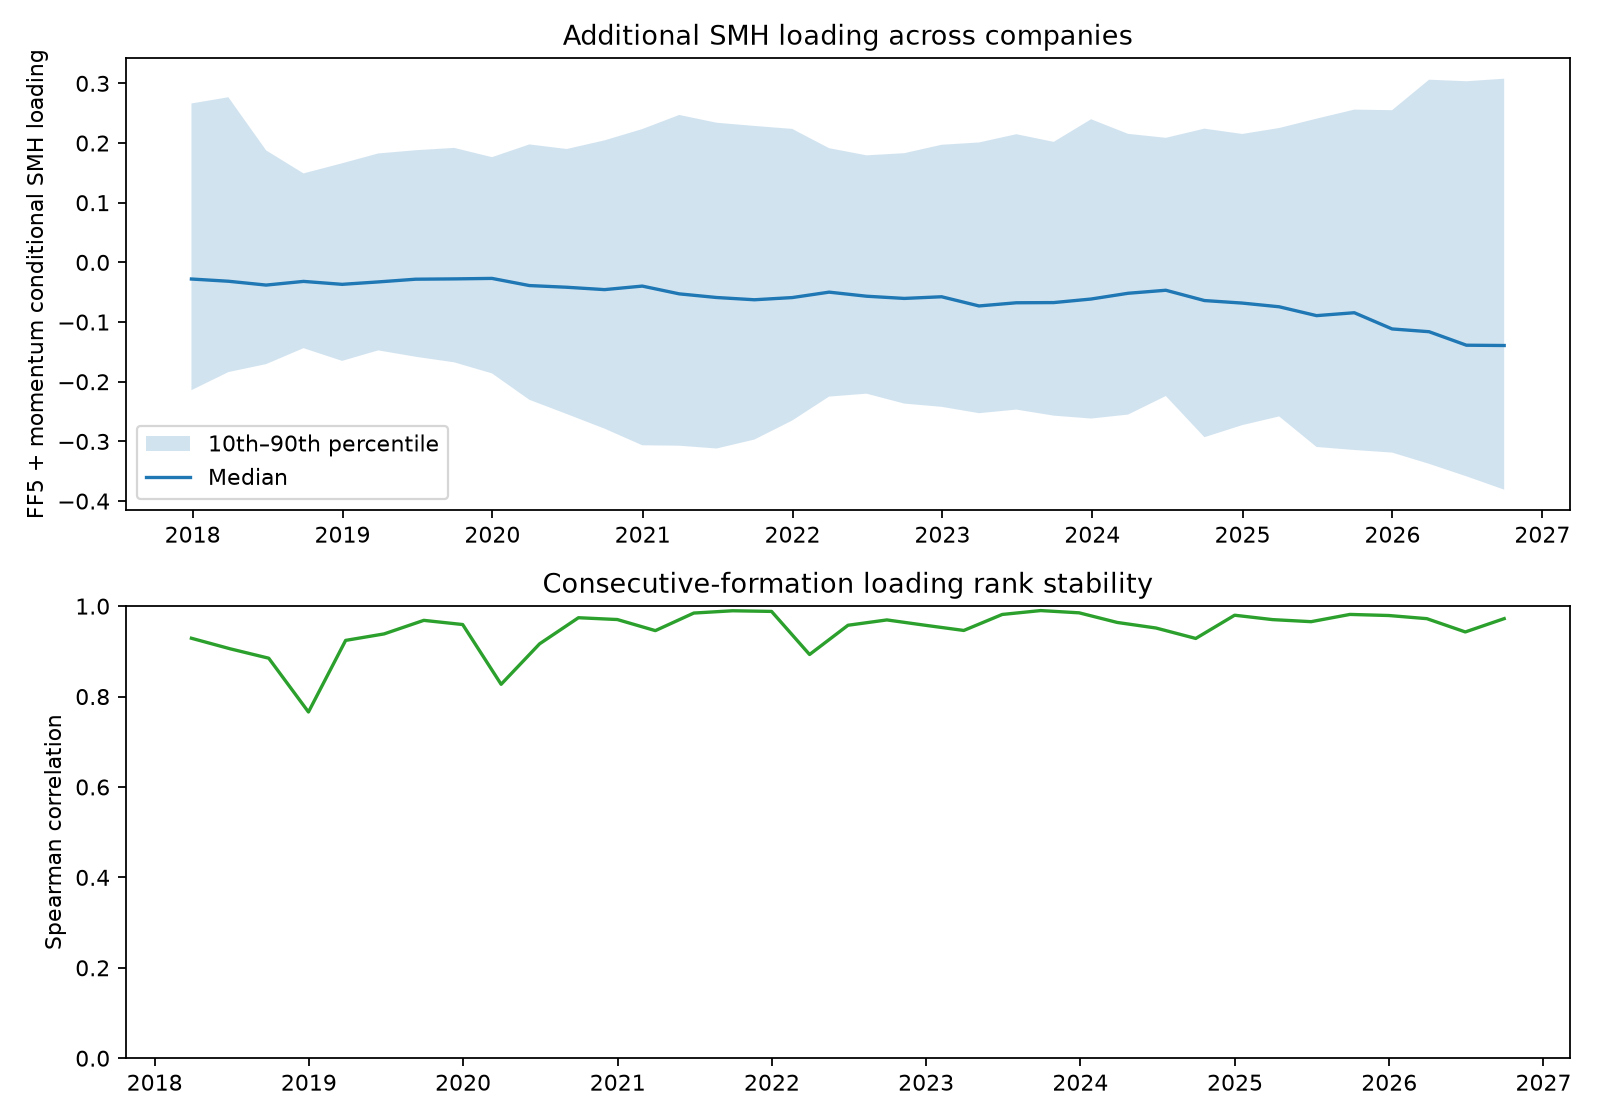

In [7]:
display(Image(filename=str(settings.repository_root_folder / 'results/panel/loading_stability.png'), width=1000))

**Predictor illustration — overlapping information in the characteristics.**
The existing heatmap shows why size, liquidity and exposures need conditional
comparisons: several characteristics are strongly correlated. It includes ordinary
and downside beta as context; those are not additional inputs in the principal
equation above. Correlations use paired eligible samples and are descriptive,
not causal effects or evidence of forecast skill. Source: existing publication
figure 03, checked against this checkout's `correlations_504.csv`.


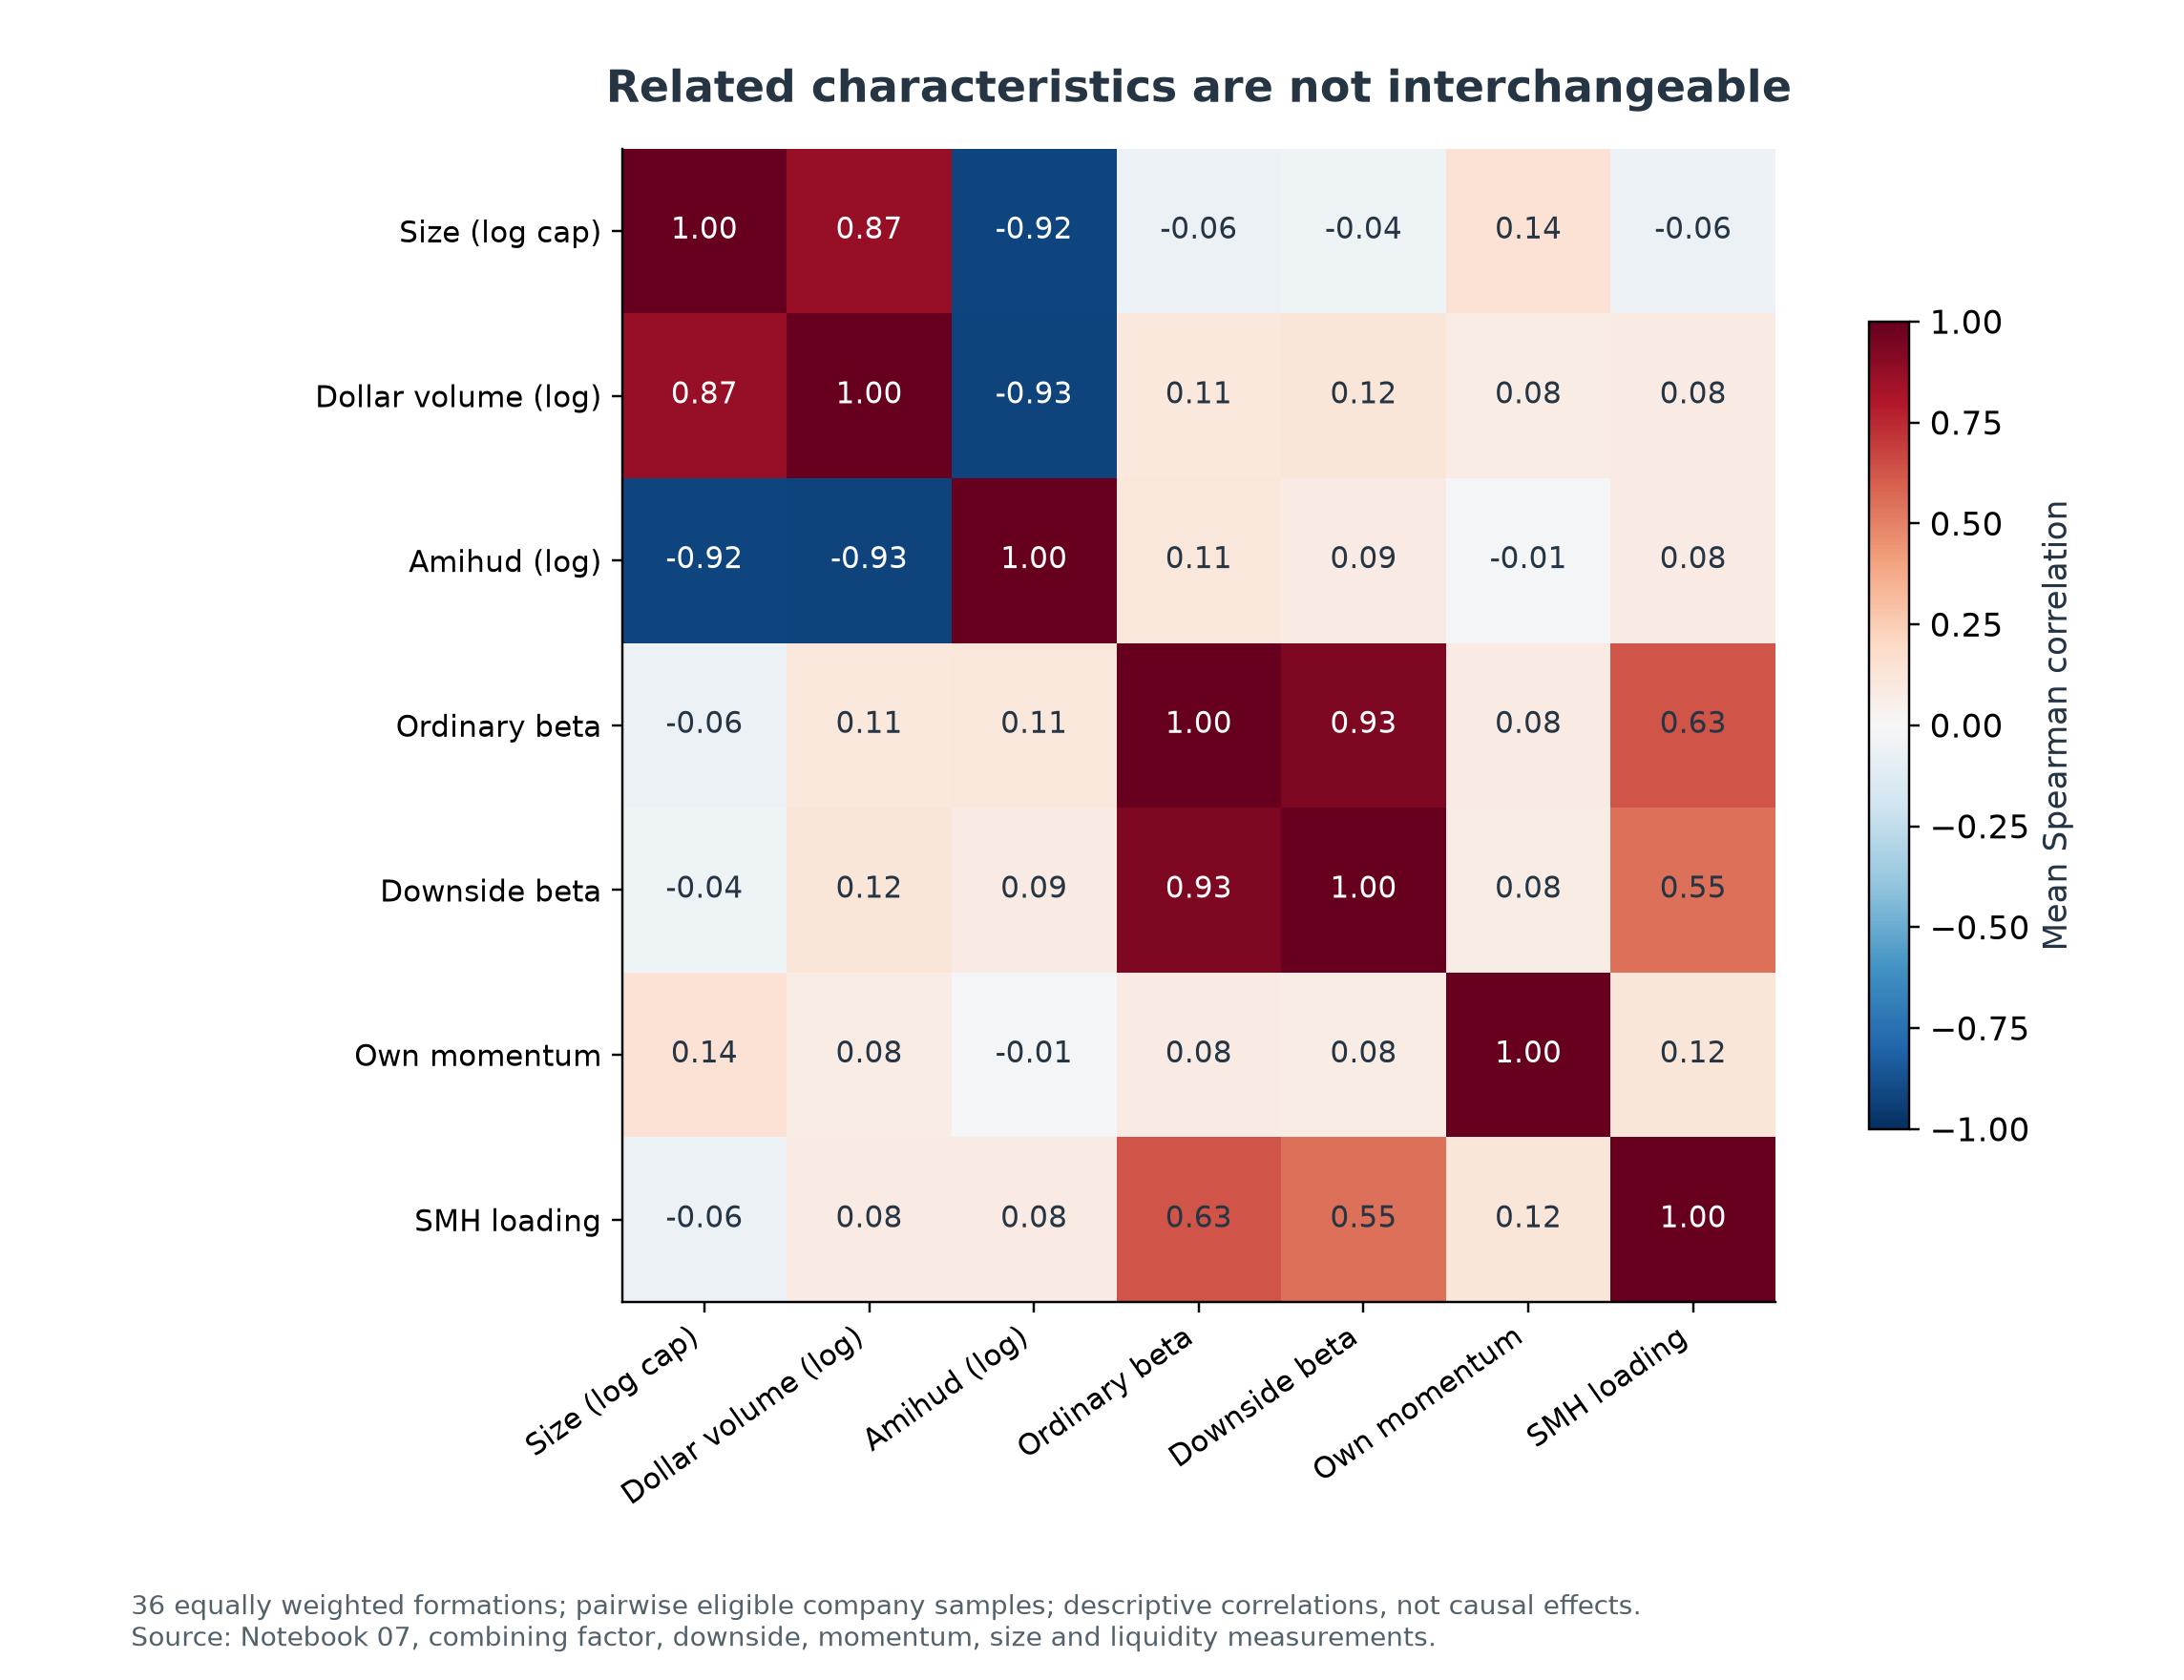

In [8]:
display(Image(filename=str(settings.repository_root_folder / 'results/publication/03_characteristic_overlap.png'), width=1000))

## 3. Matched comparisons and forecast scores

Forecast loss is the cross-sectional MSE of log volatility. For each quarter,
relative improvement is $1-\mathrm{MSE}_{E,t}/\mathrm{MSE}_{R,t}$; positive values
favor the extended model. **Association** fits use the same quarter's observed
outcomes and are labeled separately from the expanding **forecast** fits.

Industry category pooling and all numeric scaling use the training sample only.
Unseen evaluation categories use the omitted-category intercept and are counted.
The frozen retrospective factor vintage does not establish real-time publication
availability at each historical formation.


In [9]:
def _metrics(actual, predicted):
    errors = actual - predicted
    total_variation = np.sum((actual - actual.mean()) ** 2)
    return {"mse": np.mean(errors ** 2), "mae": np.mean(np.abs(errors)),
            "r_squared": 1 - np.sum(errors ** 2) / total_variation if total_variation > 0 else np.nan,
            "spearman": pd.Series(actual).corr(pd.Series(predicted), method="spearman")}

def evaluate_comparison(data, specification, outcome):
    """Paired per-quarter association and expanding forecast fits on identical samples."""
    source = data.copy()
    if specification["sample"] == "nonsemiconductors":
        source = source[source.gics_sub_industry_code.ne(settings.mechanical_overlap_subindustry_code)]
    elif specification["sample"] == "exclude_events":
        source = source[~source.ticker.isin(settings.event_convention_sensitivity_tickers)]
    columns = specification["extended_columns"]
    sample = source.dropna(subset=[outcome, *columns, "gics_sector_code", "gics_industry_group_code"])
    quarterly_rows, coefficients, predictions = [], [], []
    for formation, test in sample.groupby("formation_date", sort=True):
        possible = source[source.formation_date.eq(formation)]
        historical = sample[(sample.outcome_last_session <= formation) & (sample.formation_date < formation)]
        training_quarters = historical.formation_date.nunique()
        for analysis in ["association", "forecast"]:
            training = test if analysis == "association" else historical
            if len(test) <= len(columns) + 12 or (analysis == "forecast" and training_quarters < settings.forecast_minimum_training_quarters):
                continue
            restricted = fit_predict_linear(training, test, specification["restricted_columns"], outcome, specification["controls"])
            extended = fit_predict_linear(training, test, columns, outcome, specification["controls"])
            actual = test[outcome].to_numpy(dtype=float)
            low_metrics, high_metrics = _metrics(actual, restricted["prediction"]), _metrics(actual, extended["prediction"])
            common = {"formation_date": formation, "outcome_block": test.outcome_block.iloc[0],
                      "analysis": analysis, "comparison": specification["comparison"], "outcome": outcome,
                      "controls": specification["controls"], "sample": specification["sample"],
                      "exploratory": specification["exploratory"]}
            quarterly_rows.append({**common, "companies": len(test), "possible_companies": len(possible),
                                   "excluded_missing": len(possible) - len(test),
                                   "represented_snapshot_weight": test.issuer_snapshot_weight.sum(),
                                   "training_rows": len(training), "training_quarters": 1 if analysis == "association" else training_quarters,
                                   "latest_training_outcome_end": training.outcome_end.max(),
                                   "latest_training_outcome_last_session": training.outcome_last_session.max(),
                                   "restricted_rank": restricted["rank"], "extended_rank": extended["rank"],
                                   "extended_parameters": extended["parameters"],
                                   "unseen_control_rows": extended["unseen_control_rows"],
                                   "pooled_industry_rows": extended["pooled_industry_rows"],
                                   "pooled_industry_groups": extended["pooled_industry_groups"],
                                   **{f"restricted_{name}": value for name, value in low_metrics.items()},
                                   **{f"extended_{name}": value for name, value in high_metrics.items()},
                                   "mse_improvement": low_metrics["mse"] - high_metrics["mse"],
                                   "relative_mse_improvement": 1 - high_metrics["mse"] / low_metrics["mse"],
                                   "r_squared_improvement": high_metrics["r_squared"] - low_metrics["r_squared"]})
            for model, fit in [("restricted", restricted), ("extended", extended)]:
                coefficients.append(fit["coefficients"].assign(**common, model=model))
            if analysis == "forecast":
                prediction_table = test[["formation_date", "ticker", "cik", "outcome_block"]].copy()
                prediction_table["comparison"] = specification["comparison"]
                prediction_table["outcome"] = outcome
                prediction_table["actual"] = actual
                prediction_table["restricted_prediction"] = restricted["prediction"]
                prediction_table["extended_prediction"] = extended["prediction"]
                predictions.append(prediction_table)
    return {"quarters": pd.DataFrame(quarterly_rows),
            "coefficients": pd.concat(coefficients, ignore_index=True) if coefficients else pd.DataFrame(),
            "predictions": pd.concat(predictions, ignore_index=True) if predictions else pd.DataFrame()}

**Forecast-score illustration — positive means lower error.** The existing chart
shows mean quarterly relative MSE reductions for next-quarter log residual
volatility using 504-session exposures. Above zero, the extension improves its
matched restricted model; below zero, it worsens it. Bars average quarter-level
relative improvements, rather than pooling company errors across time. The variance
component is exploratory. These are chronological forecasts, not same-quarter
association fits. Source: the current research report's forecast comparison.


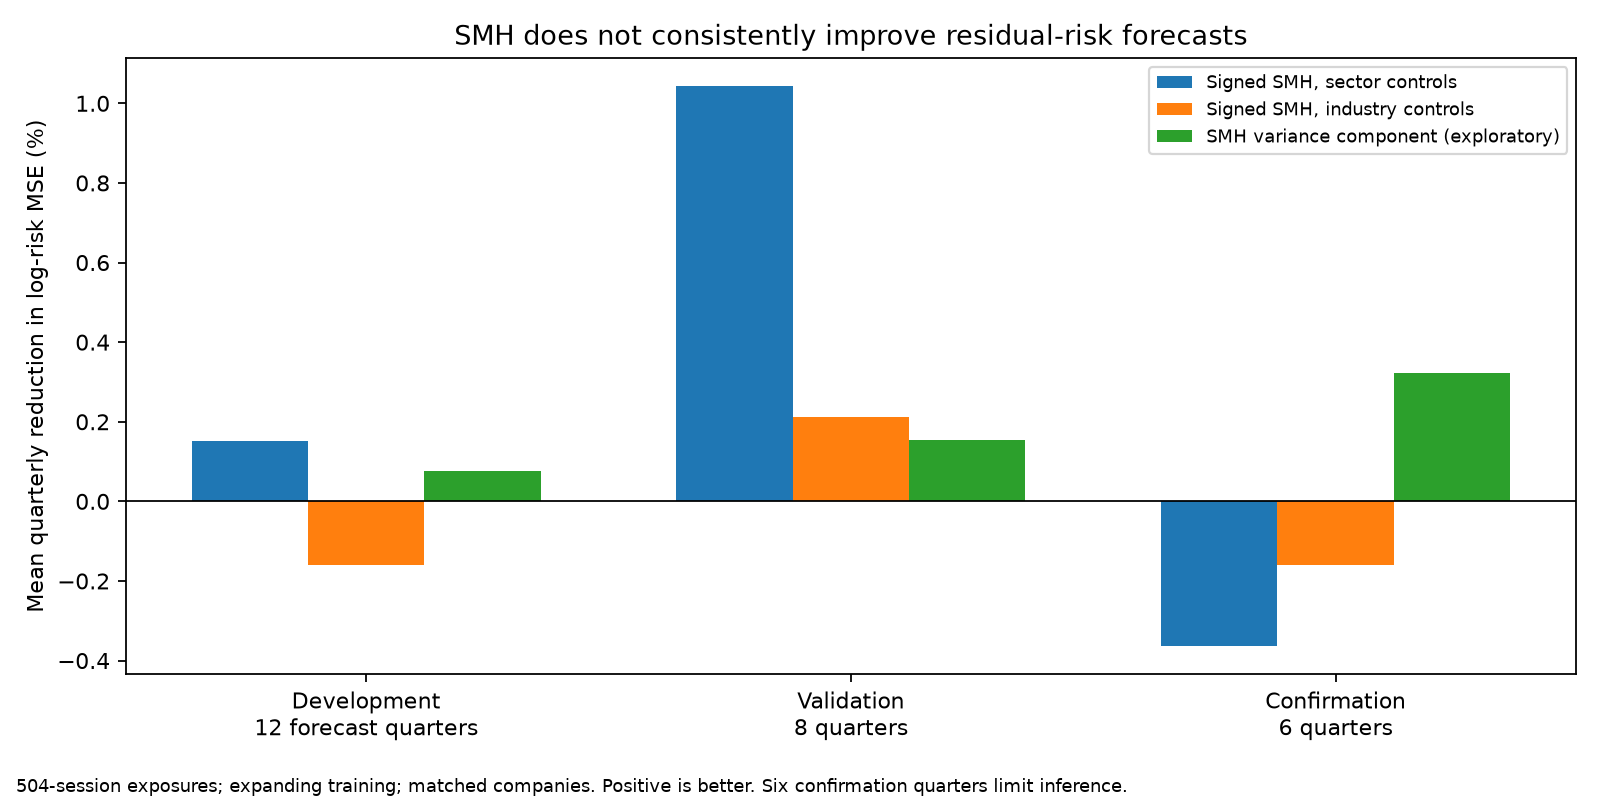

In [10]:
display(Image(filename=str(settings.repository_root_folder / 'results/report/forward_residual_risk.png'), width=1000))

### Spot-check a reported forecast improvement

This uses saved study predictions, separately from the full local recomputation in section 5. It connects paired MSE scores to one quarter's company forecasts.


In [11]:
import pandas as pd
from quiet_index_500 import settings
pred = pd.read_csv(settings.licensed_results_folder / 'forward_tests/predictions_504_residual_volatility.csv')
sample = pred[pred.comparison.eq('semiconductor') & pred.formation_date.eq('2024-12-31')]
restricted_mse = ((sample.actual - sample.restricted_prediction)**2).mean()
extended_mse = ((sample.actual - sample.extended_prediction)**2).mean()
pd.Series({'companies': len(sample), 'restricted_mse': restricted_mse, 'extended_mse': extended_mse,
           'quarter_mse_reduction_percent': 100 * (1 - extended_mse / restricted_mse)})

companies                        489.000000
restricted_mse                     0.089128
extended_mse                       0.088760
quarter_mse_reduction_percent      0.413579
dtype: float64

## 4. Quarter-level inference

Quarter scores receive equal weight. Newey-West uncertainty and four-quarter
moving/circular block bootstraps condition on the estimated exposures and fitted
forecasts. They preserve cross-sectional shocks within each quarter. Only six
confirmation quarters are available; the intervals provide limited independent evidence.


In [12]:
def _block_resample_indices(starts, block_length, count, circular=False):
    indices = (starts[:, :, None] + np.arange(block_length)).reshape(len(starts), -1)[:, :count]
    return indices % count if circular else indices

def time_dependence_inference(values, seed=settings.bootstrap_random_seed):
    """Mean, Newey-West uncertainty and moving-block bootstrap over ordered quarter scores."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    count = len(values)
    if count == 0:
        return {"quarters": 0}
    average = values.mean()
    centered = values - average
    long_run_variance = centered @ centered / count
    lags = min(settings.newey_west_lags, count - 1)
    for lag in range(1, lags + 1):
        weight = 1 - lag / (lags + 1)
        long_run_variance += 2 * weight * (centered[lag:] @ centered[:-lag]) / count
    standard_error = np.sqrt(max(long_run_variance, 0) / count)
    block_length = min(settings.bootstrap_block_length, count)
    generator = np.random.default_rng(seed)
    block_starts = generator.integers(0, count - block_length + 1,
                                     size=(settings.bootstrap_replications, int(np.ceil(count / block_length))))
    indices = _block_resample_indices(block_starts, block_length, count)
    bootstrapped_means = values[indices].mean(axis=1)
    circular_generator = np.random.default_rng(seed)
    circular_starts = circular_generator.integers(0, count,
                         size=(settings.bootstrap_replications, int(np.ceil(count / block_length))))
    circular_means = values[_block_resample_indices(circular_starts, block_length, count, circular=True)].mean(axis=1)
    return {"quarters": count, "mean": average, "newey_west_se": standard_error,
            "newey_west_t": average / standard_error if standard_error > 0 else np.nan,
            "bootstrap_low": np.quantile(bootstrapped_means, 0.025),
            "bootstrap_high": np.quantile(bootstrapped_means, 0.975),
            "circular_bootstrap_low": np.quantile(circular_means, 0.025),
            "circular_bootstrap_high": np.quantile(circular_means, 0.975),
            "positive_quarter_share": np.mean(values > 0), "newey_west_lags": lags,
            "bootstrap_block_length": block_length, "bootstrap_replications": settings.bootstrap_replications,
            "inference_conditions": "fixed estimated exposures; common quarter shocks preserved"}

def summarize_comparisons(quarterly):
    """Inference by development, validation, confirmation and pooled evaluation blocks."""
    output = []
    for keys, group in quarterly.groupby(["window_sessions", "analysis", "comparison", "outcome", "exploratory"], sort=True):
        common = dict(zip(["window_sessions", "analysis", "comparison", "outcome", "exploratory"], keys))
        blocks = [("all", group), *list(group.groupby("outcome_block", sort=True))]
        for block, rows in blocks:
            rows = rows.sort_values("formation_date")
            for metric in ["mse_improvement", "relative_mse_improvement", "r_squared_improvement"]:
                output.append({**common, "outcome_block": block, "metric": metric,
                               "mean_companies": rows.companies.mean(),
                               **time_dependence_inference(rows[metric])})
    return pd.DataFrame(output)

def summarize_added_coefficients(coefficients):
    """Quarterly mean association slopes for added terms on the within-quarter SD scale."""
    selected = coefficients[coefficients.analysis.eq("association") & coefficients.model.eq("extended")]
    term_by_comparison = {
        "semiconductor": ["m4_smh_excess"], "semiconductor_industry": ["m4_smh_excess"],
        "semiconductor_no_size": ["m4_smh_excess"], "semiconductor_nonsemiconductors": ["m4_smh_excess"],
        "semiconductor_exclude_events": ["m4_smh_excess"], "liquidity": ["log_amihud_252_per_million"],
        "dollar_volume": ["log_median_dollar_volume_60"], "size_interaction": ["size_smh_interaction"],
        "semiconductor_variance_component": ["semiconductor_variance_component"],
        "standard_styles": standard_style_columns,
    }
    output = []
    for keys, group in selected.groupby(["window_sessions", "comparison", "outcome", "term", "exploratory"], sort=True):
        common = dict(zip(["window_sessions", "comparison", "outcome", "term", "exploratory"], keys))
        if common["term"] not in term_by_comparison[common["comparison"]]:
            continue
        for block, rows in [("all", group), *list(group.groupby("outcome_block", sort=True))]:
            output.append({**common, "outcome_block": block,
                           "scale": "log volatility change per within-quarter characteristic SD, conditional on other columns",
                           **time_dependence_inference(rows.sort_values("formation_date").coefficient)})
    return pd.DataFrame(output)

**Uncertainty illustration — point estimates and whole-quarter block intervals.**
Dots are equal-quarter mean relative MSE improvements for log residual volatility;
lines are conditional 95% circular block-bootstrap intervals. Zero marks no
improvement. Validation has eight quarters and confirmation only six; hundreds
of companies do not create more independent quarter shocks. Each comparison has
its own paired sample and restricted model: the liquidity extensions add to the
SMH model. Dollar volume remains exploratory. These are circular intervals, not
the noncircular moving-block intervals also returned by the inference function.
Source: existing publication figure 04; all eight plotted estimates and
intervals were checked against this checkout's `paired_inference.csv` before reuse.


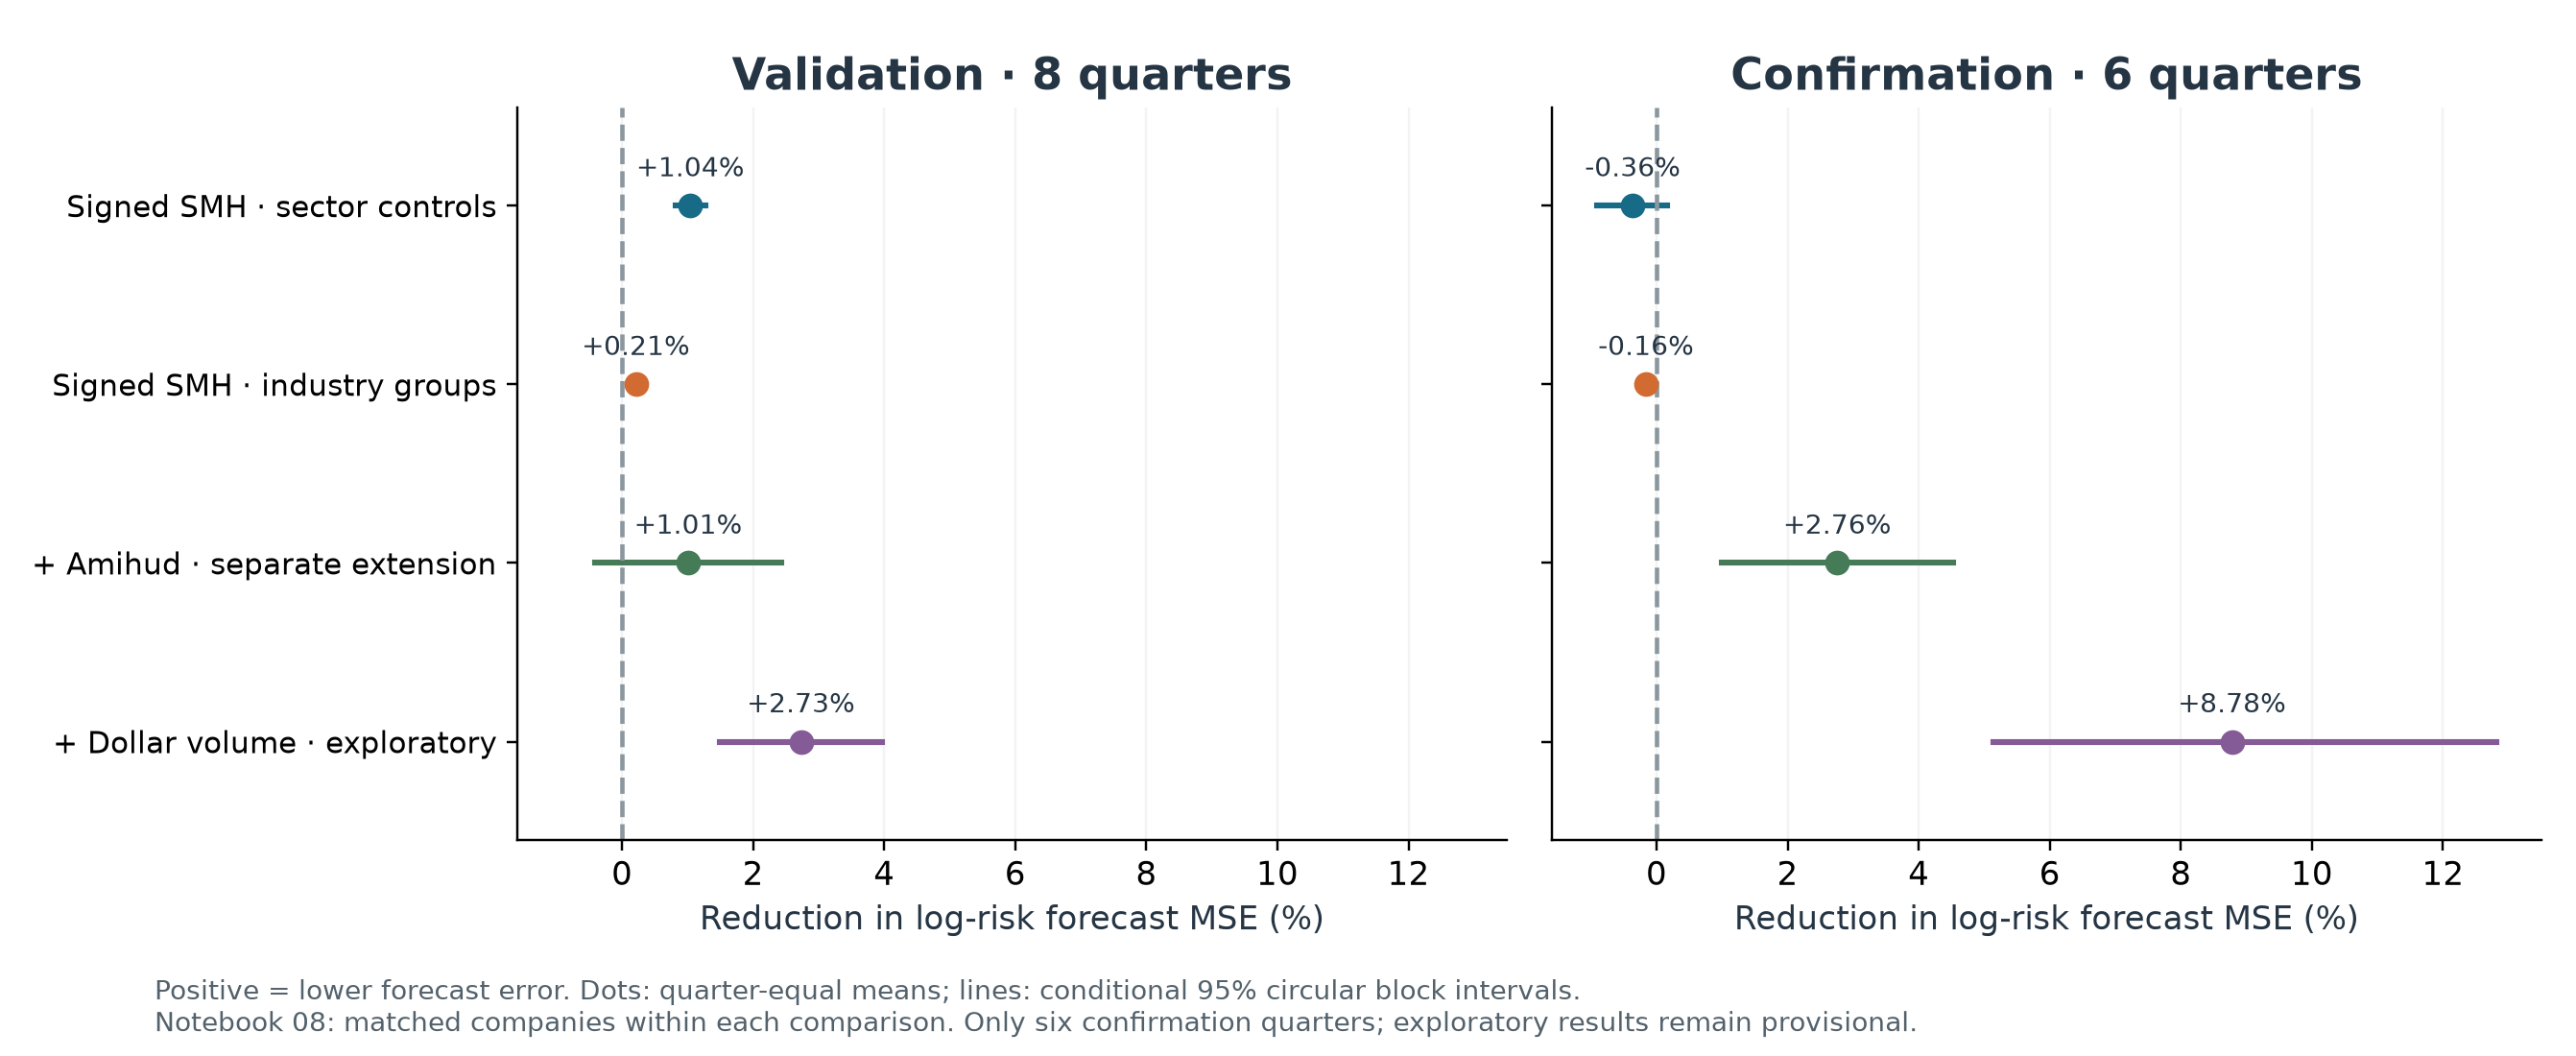

In [13]:
display(Image(filename=str(settings.repository_root_folder / 'results/publication/04_forward_risk.png'), width=1000))

## 5. Source calculations from frozen inputs

These cells call the functions defined above, starting with the saved company
characteristics and daily return/factor panels. They recompute outcomes,
associations, forecasts, scores and inference for both exposure windows.


In [14]:
daily_returns = loader.load_daily_returns()
factors = loader.load_factors()
windows = [settings.main_window_sessions, settings.sensitivity_window_sessions]
outcomes_by_window = {}
quarter_tables, coefficient_tables, prediction_tables = [], [], []

for window in windows:
    panel_path = settings.licensed_results_folder / "panel" / f"company_panel_{window}.csv"
    company_panel = pd.read_csv(panel_path, parse_dates=["formation_date"])
    outcomes = forward_outcomes(company_panel, daily_returns, factors)
    outcomes_by_window[window] = outcomes
    data = company_panel.merge(
        outcomes, on=["formation_date", "ticker", "cik"], validate="one_to_one"
    )
    data["size_smh_interaction"] = data.log_market_cap * data.m4_smh_excess
    data["semiconductor_variance_component"] = (
        data.m4_smh_excess ** 2 * data.smh_residual_volatility ** 2
    )
    for outcome in outcome_columns:
        for specification in comparison_specifications(window):
            result = evaluate_comparison(data, specification, outcome)
            quarter_tables.append(result["quarters"].assign(window_sessions=window))
            coefficient_tables.append(result["coefficients"].assign(window_sessions=window))
            prediction_tables.append(result["predictions"].assign(window_sessions=window))

quarterly = pd.concat(quarter_tables, ignore_index=True)
coefficients = pd.concat(coefficient_tables, ignore_index=True)
predictions = pd.concat(prediction_tables, ignore_index=True)
inference = summarize_comparisons(quarterly)
coefficient_inference = summarize_added_coefficients(coefficients)

forecast_quarters = quarterly.loc[quarterly.analysis.eq("forecast")]
assert (forecast_quarters.latest_training_outcome_last_session <= forecast_quarters.formation_date).all()
display(quarterly.groupby(["window_sessions", "analysis"])["formation_date"].nunique().rename("quarters"))

/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_10255/999967660.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["size_smh_interaction"] = data.log_market_cap * data.m4_smh_excess
/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_10255/999967660.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["semiconductor_variance_component"] = (


/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_10255/999967660.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["size_smh_interaction"] = data.log_market_cap * data.m4_smh_excess
/var/folders/fv/8kgvjzz53_s0kstrbq5d16vw0000gn/T/ipykernel_10255/999967660.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data["semiconductor_variance_component"] = (


window_sessions  analysis   
252              association    34
                 forecast       26
504              association    34
                 forecast       26
Name: quarters, dtype: int64

In [15]:
# Principal confirmation forecast comparisons, recomputed above.
confirmation = inference.loc[
    inference.analysis.eq("forecast")
    & inference.comparison.isin(["semiconductor", "semiconductor_industry", "semiconductor_no_size"])
    & inference.outcome_block.eq("confirmation")
    & inference.metric.eq("relative_mse_improvement")
]
display(confirmation)

,window_sessions,analysis,comparison,outcome,exploratory,outcome_block,metric,mean_companies,quarters,mean,...,newey_west_t,bootstrap_low,bootstrap_high,circular_bootstrap_low,circular_bootstrap_high,positive_quarter_share,newey_west_lags,bootstrap_block_length,bootstrap_replications,inference_conditions
172,252,forecast,semiconductor,log_forward_residual_volatility,False,confirmation,relative_mse_improvement,493.333333,6,-0.006623,...,-2.209319,-0.007896,-0.001242,-0.012137,-0.001108,0.166667,4,4,2000,fixed estimated exposures; common quarter shoc...
184,252,forecast,semiconductor,log_forward_total_volatility,False,confirmation,relative_mse_improvement,493.333333,6,0.000652,...,0.201502,0.000652,0.009464,-0.008160,0.007554,0.500000,4,4,2000,fixed estimated exposures; common quarter shoc...
196,252,forecast,semiconductor_industry,log_forward_residual_volatility,False,confirmation,relative_mse_improvement,493.333333,6,0.000528,...,1.117704,-0.000375,0.000528,-0.000290,0.001431,0.666667,4,4,2000,fixed estimated exposures; common quarter shoc...
208,252,forecast,semiconductor_industry,log_forward_total_volatility,False,confirmation,relative_mse_improvement,493.333333,6,0.000155,...,0.139308,0.000155,0.003232,-0.002923,0.002603,0.500000,4,4,2000,fixed estimated exposures; common quarter shoc...
220,252,forecast,semiconductor_no_size,log_forward_residual_volatility,False,confirmation,relative_mse_improvement,494.166667,6,-0.006601,...,-2.147138,-0.008191,-0.001413,-0.011945,-0.001257,0.166667,4,4,2000,fixed estimated exposures; common quarter shoc...
232,252,forecast,semiconductor_no_size,log_forward_total_volatility,False,confirmation,relative_mse_improvement,494.166667,6,0.000727,...,0.229489,0.000727,0.008964,-0.007509,0.007311,0.500000,4,4,2000,fixed estimated exposures; common quarter shoc...
580,504,forecast,semiconductor,log_forward_residual_volatility,False,confirmation,relative_mse_improvement,490.833333,6,-0.003626,...,-1.320790,-0.008826,0.000827,-0.009125,0.001574,0.333333,4,4,2000,fixed estimated exposures; common quarter shoc...
592,504,forecast,semiconductor,log_forward_total_volatility,False,confirmation,relative_mse_improvement,490.833333,6,0.006472,...,4.491892,0.005836,0.009200,0.004064,0.009200,0.833333,4,4,2000,fixed estimated exposures; common quarter shoc...
628,504,forecast,semiconductor_industry,log_forward_residual_volatility,False,confirmation,relative_mse_improvement,490.833333,6,-0.001588,...,-4.774979,-0.002034,-0.001260,-0.002399,-0.000778,0.000000,4,4,2000,fixed estimated exposures; common quarter shoc...
640,504,forecast,semiconductor_industry,log_forward_total_volatility,False,confirmation,relative_mse_improvement,490.833333,6,0.005482,...,8.959163,0.005197,0.006873,0.003874,0.007090,1.000000,4,4,2000,fixed estimated exposures; common quarter shoc...


**Reading the recomputed table.** `mean` is relative MSE improvement as a
fraction; multiply by 100 for the percentage axes in sections 3–4.
`bootstrap_low/high` are moving-block endpoints; `circular_bootstrap_low/high`
are circular-block endpoints. This table includes both exposure windows and risk
targets, whereas the existing charts show 504-session residual-risk comparisons.
The forecast-quarter count above is separate from the association-quarter count.


## 6. Inspect a fitted equation and its company forecasts

Select one main-window semiconductor forecast for log residual volatility. The
coefficients below use the training-standardized predictor scale in the boxed
equation; `training_mean` and `training_scale` show the corresponding transformation.
The saved pipeline equivalents are `results/licensed/forward_tests/coefficients_504.csv`
and `predictions_504_residual_volatility.csv`.

**Reading these tables.** The first table exposes the intercept, standardized
slopes, category coefficients and training transformations in section 2's equation.
In the second, `actual`, `restricted_prediction` and `extended_prediction` are
log volatility; `extended_volatility_prediction` exponentiates the extended forecast
into annualized decimal volatility. These individual forecasts differ from the
aggregate scores and uncertainty shown in the earlier figures.


In [16]:
selected_window = settings.main_window_sessions
selected_outcome = "log_forward_residual_volatility"
selected_comparison = "semiconductor"
selected_formation = predictions.loc[
    predictions.window_sessions.eq(selected_window)
    & predictions.outcome.eq(selected_outcome)
    & predictions.comparison.eq(selected_comparison), "formation_date"
].max()

fitted_equation = coefficients.loc[
    coefficients.window_sessions.eq(selected_window)
    & coefficients.formation_date.eq(selected_formation)
    & coefficients.analysis.eq("forecast")
    & coefficients.comparison.eq(selected_comparison)
    & coefficients.outcome.eq(selected_outcome)
    & coefficients.model.eq("extended"),
    ["formation_date", "term", "coefficient", "training_mean", "training_scale"]
]
company_forecasts = predictions.loc[
    predictions.window_sessions.eq(selected_window)
    & predictions.formation_date.eq(selected_formation)
    & predictions.comparison.eq(selected_comparison)
    & predictions.outcome.eq(selected_outcome)
].copy()
company_forecasts["extended_volatility_prediction"] = np.exp(company_forecasts.extended_prediction)
display(fitted_equation)
display(company_forecasts.head(10))

,formation_date,term,coefficient,training_mean,training_scale
30579,2026-03-31,const,-1.376646,0.000000,1.000000
30580,2026-03-31,log_market_cap,-0.024178,24.255100,1.090960
30581,2026-03-31,m3_mkt_rf,0.003317,0.964375,0.301148
30582,2026-03-31,own_momentum,-0.031076,0.182540,0.411560
30583,2026-03-31,trailing_residual_volatility,0.225294,0.237341,0.093830
30584,2026-03-31,m3_smb,0.006311,0.105825,0.358758
30585,2026-03-31,m3_hml,-0.020999,0.124323,0.510599
30586,2026-03-31,m3_rmw,-0.012388,0.021906,0.471425
30587,2026-03-31,m3_cma,0.006306,0.077730,0.608317
30588,2026-03-31,m3_mom,0.018534,-0.049522,0.281167


,formation_date,ticker,cik,outcome_block,comparison,outcome,actual,restricted_prediction,extended_prediction,window_sessions,extended_volatility_prediction
149138,2026-03-31,ABT,1800,confirmation,semiconductor,log_forward_residual_volatility,-1.246179,-1.576620,-1.568009,504,0.208460
149139,2026-03-31,AMD,2488,confirmation,semiconductor,log_forward_residual_volatility,-0.576064,-1.038575,-0.989291,504,0.371840
149140,2026-03-31,APD,2969,confirmation,semiconductor,log_forward_residual_volatility,-1.304901,-1.514903,-1.524205,504,0.217794
149141,2026-03-31,SWKS,4127,confirmation,semiconductor,log_forward_residual_volatility,-0.420048,-1.138350,-1.136525,504,0.320932
149142,2026-03-31,HWM,4281,confirmation,semiconductor,log_forward_residual_volatility,-1.022292,-1.470151,-1.481378,504,0.227324
149143,2026-03-31,AEP,4904,confirmation,semiconductor,log_forward_residual_volatility,-1.607563,-1.706439,-1.695421,504,0.183522
149144,2026-03-31,AXP,4962,confirmation,semiconductor,log_forward_residual_volatility,-1.419935,-1.715681,-1.732910,504,0.176769
149145,2026-03-31,AFL,4977,confirmation,semiconductor,log_forward_residual_volatility,-1.672616,-1.748258,-1.760078,504,0.172031
149146,2026-03-31,AIG,5272,confirmation,semiconductor,log_forward_residual_volatility,-1.469638,-1.674098,-1.671686,504,0.187930
149147,2026-03-31,ADI,6281,confirmation,semiconductor,log_forward_residual_volatility,-0.856898,-1.483901,-1.471220,504,0.229645


## Findings and interpretation

Signed SMH lowers residual-risk forecast MSE by 1.04% in validation but raises it by 0.36% in confirmation. Industry controls do not rescue the latter. The Amihud extension improves confirmation by 2.76%; dollar volume improves it by 8.78% but is exploratory.

These results answer the stock-level question. Read these alongside [portfolio covariance](portfolio-covariance.ipynb) and the [cross-study synthesis](../FINDINGS.md). Percentages are changes in log-volatility forecast error, not risk reduction.

